In [13]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import zipfile
import io

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [14]:

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(url, timeout=30)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    filename = next(
        name for name in z.namelist()
        if name.endswith("SMSSpamCollection")
    )
    with z.open(filename) as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

df = df.dropna().drop_duplicates().reset_index(drop=True)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (5169, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [15]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nMessage categories:")
print(df["label"].value_counts())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5169 entries, 0 to 5168
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5169 non-null   object
 1   message  5169 non-null   object
dtypes: object(2)
memory usage: 80.9+ KB

Missing values:
label      0
message    0
dtype: int64

Message categories:
label
ham     4516
spam     653
Name: count, dtype: int64


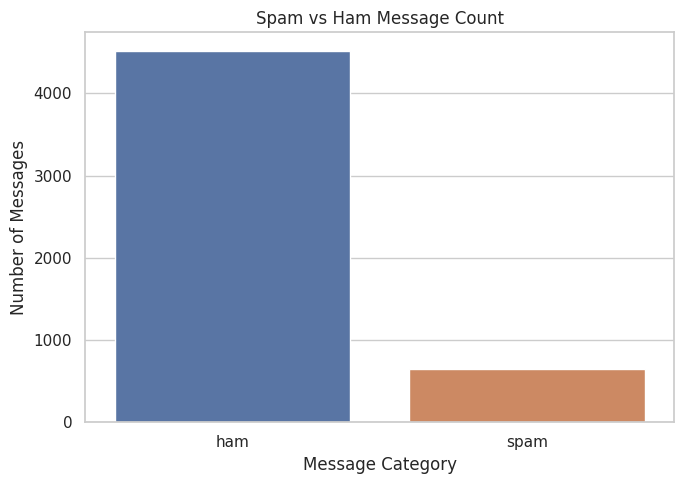

In [16]:

sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="label", hue="label",
              order=["ham", "spam"], legend=False)
plt.title("Spam vs Ham Message Count")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()


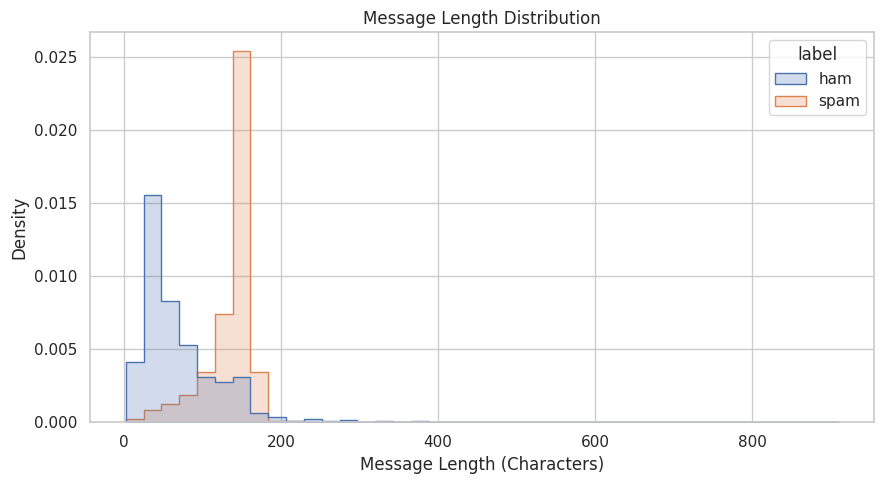

In [17]:

df["message_length"] = df["message"].str.len()

plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="message_length",
    hue="label",
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)
plt.title("Message Length Distribution")
plt.xlabel("Message Length (Characters)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


In [18]:

X = df["message"].astype(str)
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))


Training messages: 4135
Testing messages: 1034


In [19]:

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        min_df=2,
        strip_accents="unicode"
    )),
    ("classifier", MultinomialNB(alpha=0.5))
])

print("Model pipeline created successfully!")


Model pipeline created successfully!


In [20]:

model.fit(X_train, y_train)

print("Spam detection model trained successfully!")


Spam detection model trained successfully!


In [21]:

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, pos_label="spam", zero_division=0
)
recall = recall_score(
    y_test, y_pred, pos_label="spam", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, pos_label="spam", zero_division=0
)

print(f"Accuracy:        {accuracy:.2%}")
print(f"Spam Precision:  {precision:.2%}")
print(f"Spam Recall:     {recall:.2%}")
print(f"Spam F1-score:   {f1:.2%}")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test, y_pred, labels=["ham", "spam"], zero_division=0
))


Accuracy:        97.29%
Spam Precision:  100.00%
Spam Recall:     78.63%
Spam F1-score:   88.03%

Detailed Classification Report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       903
        spam       1.00      0.79      0.88       131

    accuracy                           0.97      1034
   macro avg       0.98      0.89      0.93      1034
weighted avg       0.97      0.97      0.97      1034



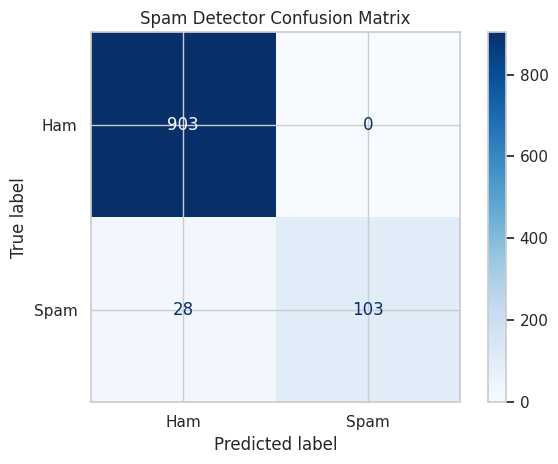

In [22]:

cm = confusion_matrix(
    y_test, y_pred, labels=["ham", "spam"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Spam Detector Confusion Matrix")
plt.tight_layout()
plt.show()


In [23]:

test_messages = [
    "Congratulations! You have won a free prize. Call now to claim.",
    "Hi, are we still meeting for lunch at 1 pm?",
    "URGENT! Claim your reward by clicking this link now.",
    "Your appointment is confirmed for tomorrow."
]

predictions = model.predict(test_messages)
probabilities = model.predict_proba(test_messages)
classes = model.named_steps["classifier"].classes_

for message, prediction, probs in zip(
    test_messages, predictions, probabilities
):
    print("Message:", message)
    print("Prediction:", prediction.upper())
    print("Class probabilities:", {
        label: round(float(prob), 3)
        for label, prob in zip(classes, probs)
    })
    print("-" * 60)


Message: Congratulations! You have won a free prize. Call now to claim.
Prediction: SPAM
Class probabilities: {np.str_('ham'): 0.011, np.str_('spam'): 0.989}
------------------------------------------------------------
Message: Hi, are we still meeting for lunch at 1 pm?
Prediction: HAM
Class probabilities: {np.str_('ham'): 0.995, np.str_('spam'): 0.005}
------------------------------------------------------------
Message: URGENT! Claim your reward by clicking this link now.
Prediction: SPAM
Class probabilities: {np.str_('ham'): 0.09, np.str_('spam'): 0.91}
------------------------------------------------------------
Message: Your appointment is confirmed for tomorrow.
Prediction: HAM
Class probabilities: {np.str_('ham'): 0.916, np.str_('spam'): 0.084}
------------------------------------------------------------
